<center>
    <p style="color: red; font-size: 20px;">Tên: Lê Thiên Hạo</p>
</center>
<center>
    <p style="color: red; font-size: 20px;">MSSV: 089206010393</p>
</center>

# Phân cụm văn bản (Text Clustering) bằng K-Means — bộ dữ liệu 20 Newsgroups

Khác với 2 notebook trước (dữ liệu số 2D), bài này áp dụng K-Means lên **văn bản thật**: các bài đăng thuộc 3 nhóm thảo luận (tôn giáo, không gian, súng đạn) trong bộ dữ liệu kinh điển *20 Newsgroups*. Nội dung chính:
- Biến văn bản thành vector số bằng nhiều cách khác nhau (TF-IDF, LSA, Hashing).
- So sánh `KMeans` và `MiniBatchKMeans` trên các cách vector hoá đó.
- Đánh giá chất lượng phân cụm bằng các chỉ số chuẩn, so với nhãn thật của dữ liệu.

## Bước 1: Import

`fetch_20newsgroups`: hàm tải bộ dữ liệu 20 Newsgroups có sẵn trong sklearn. `numpy` dùng cho các phép tính số.

In [1]:
from sklearn.datasets import fetch_20newsgroups
import numpy as np 

## Bước 2: Chọn 3 nhóm thảo luận

Thay vì dùng cả 20 nhóm gốc, chỉ giữ lại 3 nhóm rõ chủ đề, khác biệt nhau (`sci.space`, `soc.religion.christian`, `talk.politics.guns`) để bài toán phân cụm có đáp án "đúng/sai" rõ ràng, dễ đánh giá.

In [2]:
cats = ['sci.space', 'soc.religion.christian', 'talk.politics.guns']

## Bước 3: Tải dữ liệu

- `remove=("headers", "footers", "quotes")`: bỏ phần header email, chữ ký, đoạn trích dẫn — nếu giữ lại, mô hình có thể "ăn gian" dựa vào các dấu hiệu này thay vì nội dung thật.
- `subset="all"`: lấy cả phần train lẫn test.
- `shuffle=True, random_state=42`: xáo trộn thứ tự văn bản, cố định seed để tái lập được kết quả.

In [3]:
dataset = fetch_20newsgroups(
    remove=("headers", "footers", "quotes"),
    subset="all",
    categories=cats,
    shuffle=True, 
    random_state=42
)

## Bước 4: Xem tổng quan dữ liệu

`dataset.target` là **nhãn thật** (0/1/2 ứng với 3 nhóm) — chỉ dùng để **đánh giá** sau này, vì K-Means là học không giám sát (không được biết nhãn khi phân cụm). Kết quả: 2894 văn bản, chia thành 3 nhóm (`category_size` lưu số lượng mỗi nhóm, dùng so sánh về sau).

In [4]:
labels = dataset.target
unqiue_labels, category_size = np.unique(labels, return_counts=True)
true_k = unqiue_labels.shape[0]
print(f"{len(dataset.data)} documents - {true_k} categories")

2894 documents - 3 categories


## Tra cứu nhanh

`?ten_doi_tuong` là cú pháp trợ giúp (help) của Jupyter/IPython, hiển thị docstring của đối tượng — ở đây tra nhanh `collections.defaultdict` trước khi dùng ở hàm bên dưới, không ảnh hưởng luồng code chính.

In [5]:
?collections.defaultdict

Init signature: collections.defaultdict(self, /, *args, **kwargs)
Docstring:     
defaultdict(default_factory=None, /, [...]) --> dict with default factory

The default factory is called without arguments to produce
a new value when a key is not present, in __getitem__ only.
A defaultdict compares equal to a dict with the same items.
All remaining arguments are treated the same as if they were
passed to the dict constructor, including keyword arguments.
File:           ~/anaconda3/lib/python3.13/collections/__init__.py
Type:           type
Subclasses:     FreezableDefaultDict

## Tra cứu nhanh (tiếp)

Tương tự, tra `time.time` — nhưng báo `Object time.time not found` vì module `time` chưa được import (chỉ import ở cell kế tiếp), nên IPython chưa biết đối tượng này.

In [6]:
?time.time

Object `time.time` not found.


## Bước 5: Hàm đánh giá `fit_and_evaluate`

Hàm dùng chung để fit một mô hình phân cụm (`km`) trên dữ liệu `X` nhiều lần với các `random_state` khác nhau (mặc định 5 lần), rồi đo:
- **Homogeneity**: mỗi cụm có "thuần" gồm 1 nhãn thật hay bị trộn nhiều nhãn.
- **Completeness**: các văn bản cùng 1 nhãn thật có bị tách ra nhiều cụm khác nhau không.
- **V-measure**: trung bình điều hoà của Homogeneity và Completeness.
- **Adjusted Rand-Index**: độ giống nhau giữa cụm dự đoán và nhãn thật, đã hiệu chỉnh yếu tố ngẫu nhiên.
- **Silhouette Coefficient**: đo cụm có "gọn và tách biệt" hay không, chỉ dựa vào `X` và nhãn dự đoán (không cần nhãn thật, khác 4 chỉ số trên).

Kết quả (trung bình ± độ lệch chuẩn qua 5 lần chạy) được in ra và lưu vào `evaluations`/`evaluations_std` để so sánh tổng kết ở cuối bài.

In [7]:
from collections import defaultdict
from time import time

from sklearn import metrics

evaluations = []
evaluations_std = []

def fit_and_evaluate(km, X, name=None, n_nums=5):
    name = km.__class__.__name__ if name is None else name
    train_times = []
    scores = defaultdict(list)

    for seed in range(n_nums): 
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)

        train_times.append(time() - t0) 
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(metrics.adjusted_rand_score(labels, km.labels_))
        scores["Silhouette Coefficient"].append(metrics.silhouette_score(X, km.labels_, sample_size=2000))

    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name, 
        "train_time": train_times.std(), 
    }
    evaluation_std = {
        "estimator": name, 
        "train_time": train_times.std(), 
    }

    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)
    
        
        

## Bước 6: Vector hoá bằng TF-IDF

`TfidfVectorizer` biến mỗi văn bản thành 1 vector số — mỗi chiều ứng với 1 từ, giá trị cao nếu từ đó xuất hiện nhiều trong văn bản này nhưng hiếm ở các văn bản khác (càng "đặc trưng" thì trọng số càng cao).
- `max_df=0.5`: bỏ từ xuất hiện ở > 50% văn bản (quá phổ biến, không giúp phân biệt).
- `min_df=5`: bỏ từ xuất hiện ở dưới 5 văn bản (quá hiếm, dễ là nhiễu).
- `stop_words="english"`: loại các từ dừng tiếng Anh (the, is, at...).

Kết quả in ra số văn bản (`n_samples`) và số từ vựng còn lại sau lọc (`n_features`).

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_df=0.5,
    min_df=5,
    stop_words="english",
)
t0 = time()
X_tfidf = vectorizer.fit_transform(dataset.data)

print(f"vectorization done in {time() - t0:.3f} s")
print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

vectorization done in 0.362 s
n_samples: 2894, n_features: 7429


## Bước 7: Độ thưa của ma trận TF-IDF

`nnz / (n_samples × n_features)` tính tỉ lệ phần tử khác 0. Kết quả ≈ 0.008 (0.8%) — ma trận **rất thưa**, vì mỗi văn bản chỉ chứa một phần rất nhỏ trong toàn bộ từ vựng của cả tập dữ liệu.

In [9]:
print(f"{X_tfidf.nnz / np.prod(X_tfidf.shape):.3f}")

0.008


## Bước 8: Thử KMeans trực tiếp trên TF-IDF — vì sao chưa ổn

Chạy `KMeans` với `n_init=1` (chỉ khởi tạo 1 lần) qua 5 seed khác nhau, in số văn bản mỗi cụm. Kết quả rất **thất thường** giữa các lần chạy (có lần gần như dồn hết vào 1 cụm, ví dụ `[3, 2890, 1]`), so với số lượng thật khá đều `[987, 997, 910]`. Đây là minh hoạ cho việc K-Means (dựa trên khoảng cách Euclid) hoạt động kém khi dữ liệu có **quá nhiều chiều và quá thưa** như TF-IDF thô — lý do các bước sau sẽ giảm chiều dữ liệu trước khi phân cụm.

In [10]:
from sklearn.cluster import KMeans

for seed in range(5):
    kmeans = KMeans(
        n_clusters=true_k,
        max_iter=100,
        n_init=1,
        random_state=seed,
    ).fit(X_tfidf)
    cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
    print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print()
print(
    "True number of documents in each category according to the class labels: "
    f"{category_size}"
)

Number of elements assigned to each cluster: [1677  649  568]
Number of elements assigned to each cluster: [   3 2890    1]
Number of elements assigned to each cluster: [   1 2892    1]
Number of elements assigned to each cluster: [ 483  578 1833]
Number of elements assigned to each cluster: [ 398 1918  578]

True number of documents in each category according to the class labels: [987 997 910]


## Bước 9: Đánh giá KMeans trên TF-IDF (có `n_init=5`)

Lần này tăng `n_init=5` (thử 5 lần khởi tạo, giữ lại lần tốt nhất) để ổn định hơn, rồi đánh giá bằng `fit_and_evaluate`. Kết quả trong lần chạy này: V-measure ≈ 0.42, Silhouette ≈ 0.009 — vẫn khá thấp, khẳng định lại vấn đề ở bước trước: TF-IDF thô quá nhiều chiều để K-Means phân cụm tốt.

In [11]:
kmeans = KMeans(
    n_clusters=true_k,
    max_iter=100,
    n_init=5,
)

fit_and_evaluate(kmeans, X_tfidf, name="KMeans\non tf-idf vectors")

clustering done in 0.07 ± 0.01 s 
Homogeneity: 0.389 ± 0.033
Completeness: 0.461 ± 0.025
V-measure: 0.422 ± 0.030
Adjusted Rand-Index: 0.286 ± 0.052
Silhouette Coefficient: 0.009 ± 0.001


## Bước 10: Giảm chiều bằng LSA

`TruncatedSVD(n_components=100)` nén dữ liệu từ hàng chục nghìn chiều (từ vựng) xuống còn 100 "chiều tiềm ẩn" (kỹ thuật này gọi là **LSA – Latent Semantic Analysis**), giữ lại phần thông tin quan trọng nhất, giảm nhiễu. `Normalizer` chuẩn hoá mỗi vector về độ dài 1, giúp khoảng cách Euclid trên vector đã chuẩn hoá tương đương độ đo cosine — phù hợp hơn với dữ liệu văn bản. `explained_variance` cho biết % thông tin (phương sai) gốc còn giữ lại được sau khi nén.

In [12]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

lsa = make_pipeline(TruncatedSVD(n_components=100), Normalizer(copy=False))
t0 = time()
X_lsa = lsa.fit_transform(X_tfidf)
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"LSA done in {time() - t0:.3f} s")
print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

LSA done in 0.365 s
Explained variance of the SVD step: 18.6%


## Bước 11: Đánh giá KMeans trên dữ liệu đã giảm chiều (LSA)

Cùng cấu hình KMeans nhưng chạy trên `X_lsa` thay vì `X_tfidf` thô. Kết quả cải thiện rõ rệt dù chỉ dùng `n_init=1`: V-measure ≈ 0.53, Silhouette ≈ 0.033 — cao hơn hẳn Bước 9, chứng minh giảm chiều bằng LSA giúp K-Means phân cụm văn bản tốt hơn nhiều.

In [13]:
kmeans = KMeans(
    n_clusters=true_k,
    max_iter=100,
    n_init=1,
)

fit_and_evaluate(kmeans, X_lsa, name="KMeans\nwith LSA on tf-idf vectors")

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.510 ± 0.094
Completeness: 0.561 ± 0.041
V-measure: 0.533 ± 0.073
Adjusted Rand-Index: 0.479 ± 0.121
Silhouette Coefficient: 0.033 ± 0.002


## Bước 12: Thử MiniBatchKMeans

`MiniBatchKMeans` là biến thể nhanh hơn của K-Means: mỗi vòng lặp chỉ cập nhật centroid dựa trên một **lô nhỏ ngẫu nhiên** (`batch_size=1000`) thay vì toàn bộ dữ liệu — phù hợp dữ liệu lớn, đổi lại chất lượng thường thấp hơn K-Means thường. Kết quả ở đây cũng thấp hơn hẳn Bước 11 (V-measure ≈ 0.33 so với ≈ 0.53), đúng như đánh đổi tốc độ ↔ chất lượng.

In [14]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(
    n_clusters=true_k,
    n_init=1,
    init_size=1000,
    batch_size=1000,
)

fit_and_evaluate(
    minibatch_kmeans,
    X_lsa,
    name="MiniBatchKMeans\nwith LSA on tf-idf vectors",
)

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.406 ± 0.216
Completeness: 0.454 ± 0.194
V-measure: 0.421 ± 0.220
Adjusted Rand-Index: 0.392 ± 0.220
Silhouette Coefficient: 0.027 ± 0.010


## Bước 13: Diễn giải cụm — từ khoá đặc trưng mỗi cụm

Đưa centroid từ không gian LSA (100 chiều) **quay ngược** lại không gian từ vựng gốc (`inverse_transform`), sắp xếp giảm dần theo trọng số rồi lấy 10 từ cao nhất mỗi cụm. Kết quả khớp gần như hoàn hảo với 3 chủ đề ban đầu: cụm 0 toàn từ tôn giáo (god, jesus, church...), cụm 1 toàn từ không gian (space, nasa, orbit...), cụm 2 toàn từ súng đạn/chính trị (gun, fbi, government...) — cách trực quan để kiểm tra K-Means có thực sự "hiểu" đúng chủ đề hay không.

In [15]:
original_space_centroids = lsa[0].inverse_transform(kmeans.cluster_centers_)
order_centroids = original_space_centroids.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

for i in range(true_k):
    print(f"Cluster {i}: ", end="")
    for ind in order_centroids[i, :10]:
        print(f"{terms[ind]} ", end="")
    print()

Cluster 0: god jesus church christ christian christians people believe bible faith 
Cluster 1: space like just know nasa don think time orbit launch 
Cluster 2: gun fbi people guns government don batf right law weapons 


## Bước 14: Cách vector hoá thay thế — HashingVectorizer

`HashingVectorizer` dùng "hashing trick" thay vì lưu từ điển từ vựng tường minh như `TfidfVectorizer` → tiết kiệm bộ nhớ đáng kể, phù hợp dữ liệu rất lớn (đổi lại **không thể** tra ngược từ chỉ số về từ gốc như Bước 13). `TfidfTransformer` áp trọng số TF-IDF lên kết quả hashing, sau đó vẫn giảm chiều bằng LSA (`TruncatedSVD` + `Normalizer`) như trước, cho ra `X_hashed_lsa`.

In [16]:
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer

lsa_vectorizer = make_pipeline(
    HashingVectorizer(stop_words="english", n_features=50_000),
    TfidfTransformer(),
    TruncatedSVD(n_components=100, random_state=0),
    Normalizer(copy=False),
)

t0 = time()
X_hashed_lsa = lsa_vectorizer.fit_transform(dataset.data)
print(f"vectorization done in {time() - t0:.3f} s")

vectorization done in 2.035 s


## Bước 15: Đánh giá KMeans trên vector hashing + LSA

Dùng lại `kmeans` (đã tạo ở Bước 11) nhưng lần này trên `X_hashed_lsa`. Kết quả V-measure ≈ 0.51 — gần tương đương Bước 11 (TF-IDF + LSA), cho thấy hashing vẫn giữ được chất lượng phân cụm tương tự trong khi tiết kiệm bộ nhớ hơn nhiều.

In [17]:
fit_and_evaluate(kmeans, X_hashed_lsa, name="KMeans\nwith LSA on hashed vectors")

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.487 ± 0.112
Completeness: 0.550 ± 0.054
V-measure: 0.514 ± 0.089
Adjusted Rand-Index: 0.466 ± 0.160
Silhouette Coefficient: 0.031 ± 0.003


## Bước 16: Đánh giá MiniBatchKMeans trên vector hashing + LSA

Tương tự Bước 12 nhưng trên `X_hashed_lsa`. Kết quả V-measure ≈ 0.35 — vẫn thấp hơn KMeans thường, lặp lại đúng kiểu đánh đổi tốc độ/chất lượng đã thấy ở Bước 12.

In [18]:
fit_and_evaluate(
    minibatch_kmeans,
    X_hashed_lsa,
    name="MiniBatchKMeans\nwith LSA on hashed vectors",
)

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.347 ± 0.189
Completeness: 0.382 ± 0.148
V-measure: 0.354 ± 0.188
Adjusted Rand-Index: 0.356 ± 0.206
Silhouette Coefficient: 0.025 ± 0.005


## Bước 17: Biểu đồ so sánh tổng kết

Gộp toàn bộ kết quả đã lưu trong `evaluations`/`evaluations_std` qua các lần gọi `fit_and_evaluate` ở trên thành 2 biểu đồ cột ngang cạnh nhau:
- Bên trái: so sánh 5 chỉ số chất lượng phân cụm giữa 4 cấu hình đã thử.
- Bên phải: so sánh thời gian huấn luyện.

`[::-1]` đảo ngược thứ tự danh sách để cột đầu tiên hiển thị lên trên cùng biểu đồ; `xerr=df_std` vẽ thanh sai số theo độ lệch chuẩn.

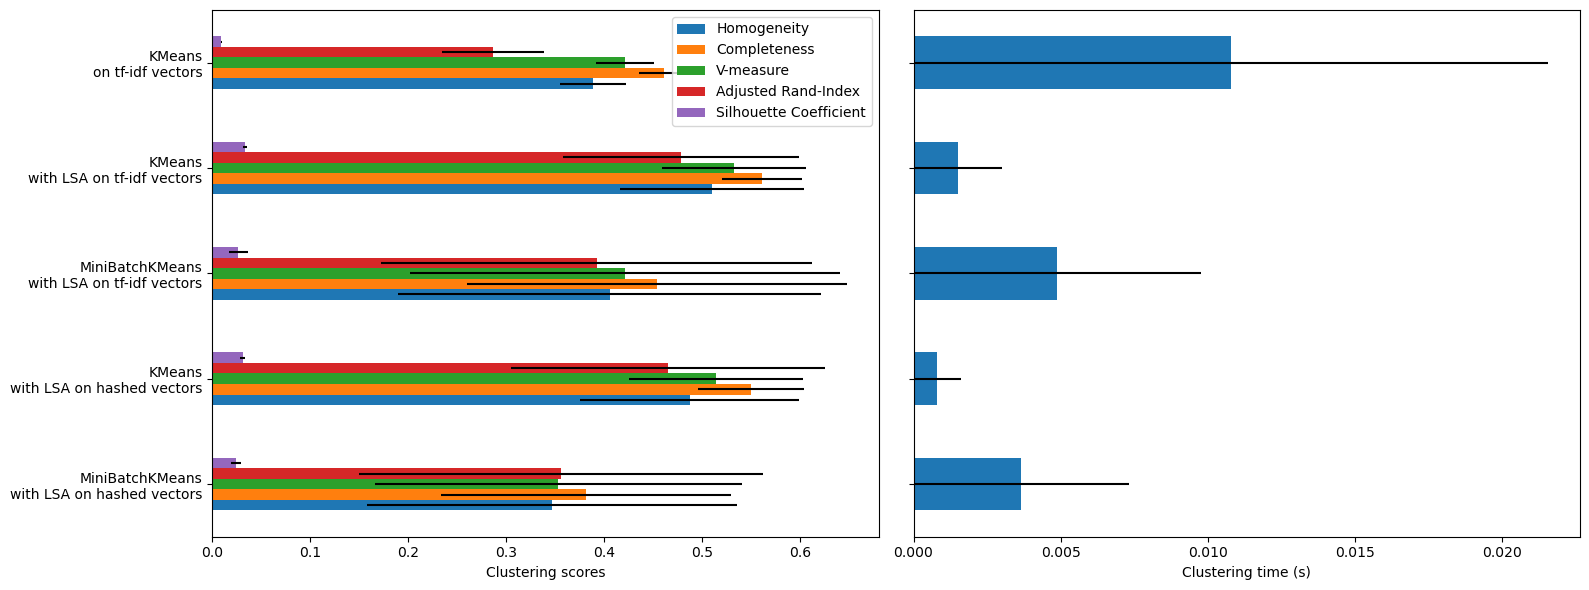

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(16, 6), sharey=True)

df = pd.DataFrame(evaluations[::-1]).set_index("estimator")
df_std = pd.DataFrame(evaluations_std[::-1]).set_index("estimator")

df.drop(
    ["train_time"],
    axis="columns",
).plot.barh(ax=ax0, xerr=df_std)
ax0.set_xlabel("Clustering scores")
ax0.set_ylabel("")

df["train_time"].plot.barh(ax=ax1, xerr=df_std["train_time"])
ax1.set_xlabel("Clustering time (s)")
plt.tight_layout()

## (Cell trống)

Cell này chưa có nội dung — có thể dùng để thử thêm, ví dụ tăng `n_components` của LSA, phân cụm với đủ cả 20 nhóm thay vì 3 nhóm, hoặc so sánh thêm với các thuật toán phân cụm khác.

## Tóm tắt

Notebook này so sánh 4 cấu hình phân cụm văn bản trên cùng bộ dữ liệu:
1. KMeans trực tiếp trên TF-IDF — kém ổn định, chất lượng thấp do quá nhiều chiều.
2. KMeans trên TF-IDF đã giảm chiều bằng LSA — cải thiện rõ rệt.
3. MiniBatchKMeans trên LSA — nhanh hơn nhưng chất lượng thấp hơn KMeans thường.
4. KMeans/MiniBatchKMeans trên vector hashing + LSA — chất lượng gần tương đương TF-IDF + LSA nhưng tiết kiệm bộ nhớ hơn.

Bài học chính: với dữ liệu văn bản nhiều chiều/thưa, **giảm chiều trước khi phân cụm (LSA)** thường quan trọng hơn việc chọn thuật toán phân cụm nào.